In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
blue_bgr = np.array([[[255, 0, 0]]], dtype=np.uint8)
hsv_blue = cv2.cvtColor(blue_bgr, cv2.COLOR_BGR2HSV)

print('HSV Value For Pure Blue:', hsv_blue[0, 0].tolist())

HSV Value For Pure Blue: [120, 255, 255]


In [3]:
lower_blue = np.array([100, 50, 50])
upper_blue = np.array([130, 255, 255])

print('Lower Blue Bound:', lower_blue.tolist())
print('Upper Blue Bound:', upper_blue.tolist())

Lower Blue Bound: [100, 50, 50]
Upper Blue Bound: [130, 255, 255]


In [5]:
uploaded = files.upload()
Video_names = list(uploaded.keys())

if len(Video_names) == 0:
  raise Exception('No Video File Uploaded')

Video_name = next(
    (name for name in Video_names if 'blue-track' in name.lower()),
    Video_names[0])
Video_path = '/content/' + Video_name

print('Input Video:', Video_name)

Saving blue-track.mp4 to blue-track (1).mp4
Input Video: blue-track (1).mp4


In [7]:
def find_largest_contour(mask, min_area=50):
  contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

  valid_contours = [contour for contour in contours if cv2.contourArea(contour) >= min_area]

  if not valid_contours:
    return None
  return max(valid_contours, key=cv2.contourArea)

cap = cv2.VideoCapture(Video_path)
if not cap.isOpened():
  raise ValueError('The Video Could Not Be Opened.')

sample_frames = []
tracked_frames = []
frame_index = 0
tracked_count = 0

while True:
  ret, frame = cap.read()
  if not ret:
    break

  hsv_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
  mask = cv2.inRange(hsv_frame, lower_blue, upper_blue)
  result = cv2.bitwise_and(frame, frame, mask=mask)

  largest_contour = find_largest_contour(mask)
  if largest_contour is not None:
    tracked_count += 1
    center, radius = cv2.minEnclosingCircle(largest_contour)
    center = (int(center[0]), int(center[1]))
    radius = int(radius)

    cv2.circle(frame, center, radius, (0, 255, 0), 2)
    cv2.circle(frame, center, 4, (0, 0, 255), -1)

  if len(sample_frames) < 6 and frame_index % 10 == 0:
    sample_frames.append((frame.copy(), mask.copy(), result.copy()))

  tracked_frames.append(frame)
  frame_index += 1

cap.release()

print('Total Frames:', frame_index)
print('Frames With Detected Blue Object:', tracked_count)

Total Frames: 260
Frames With Detected Blue Object: 260


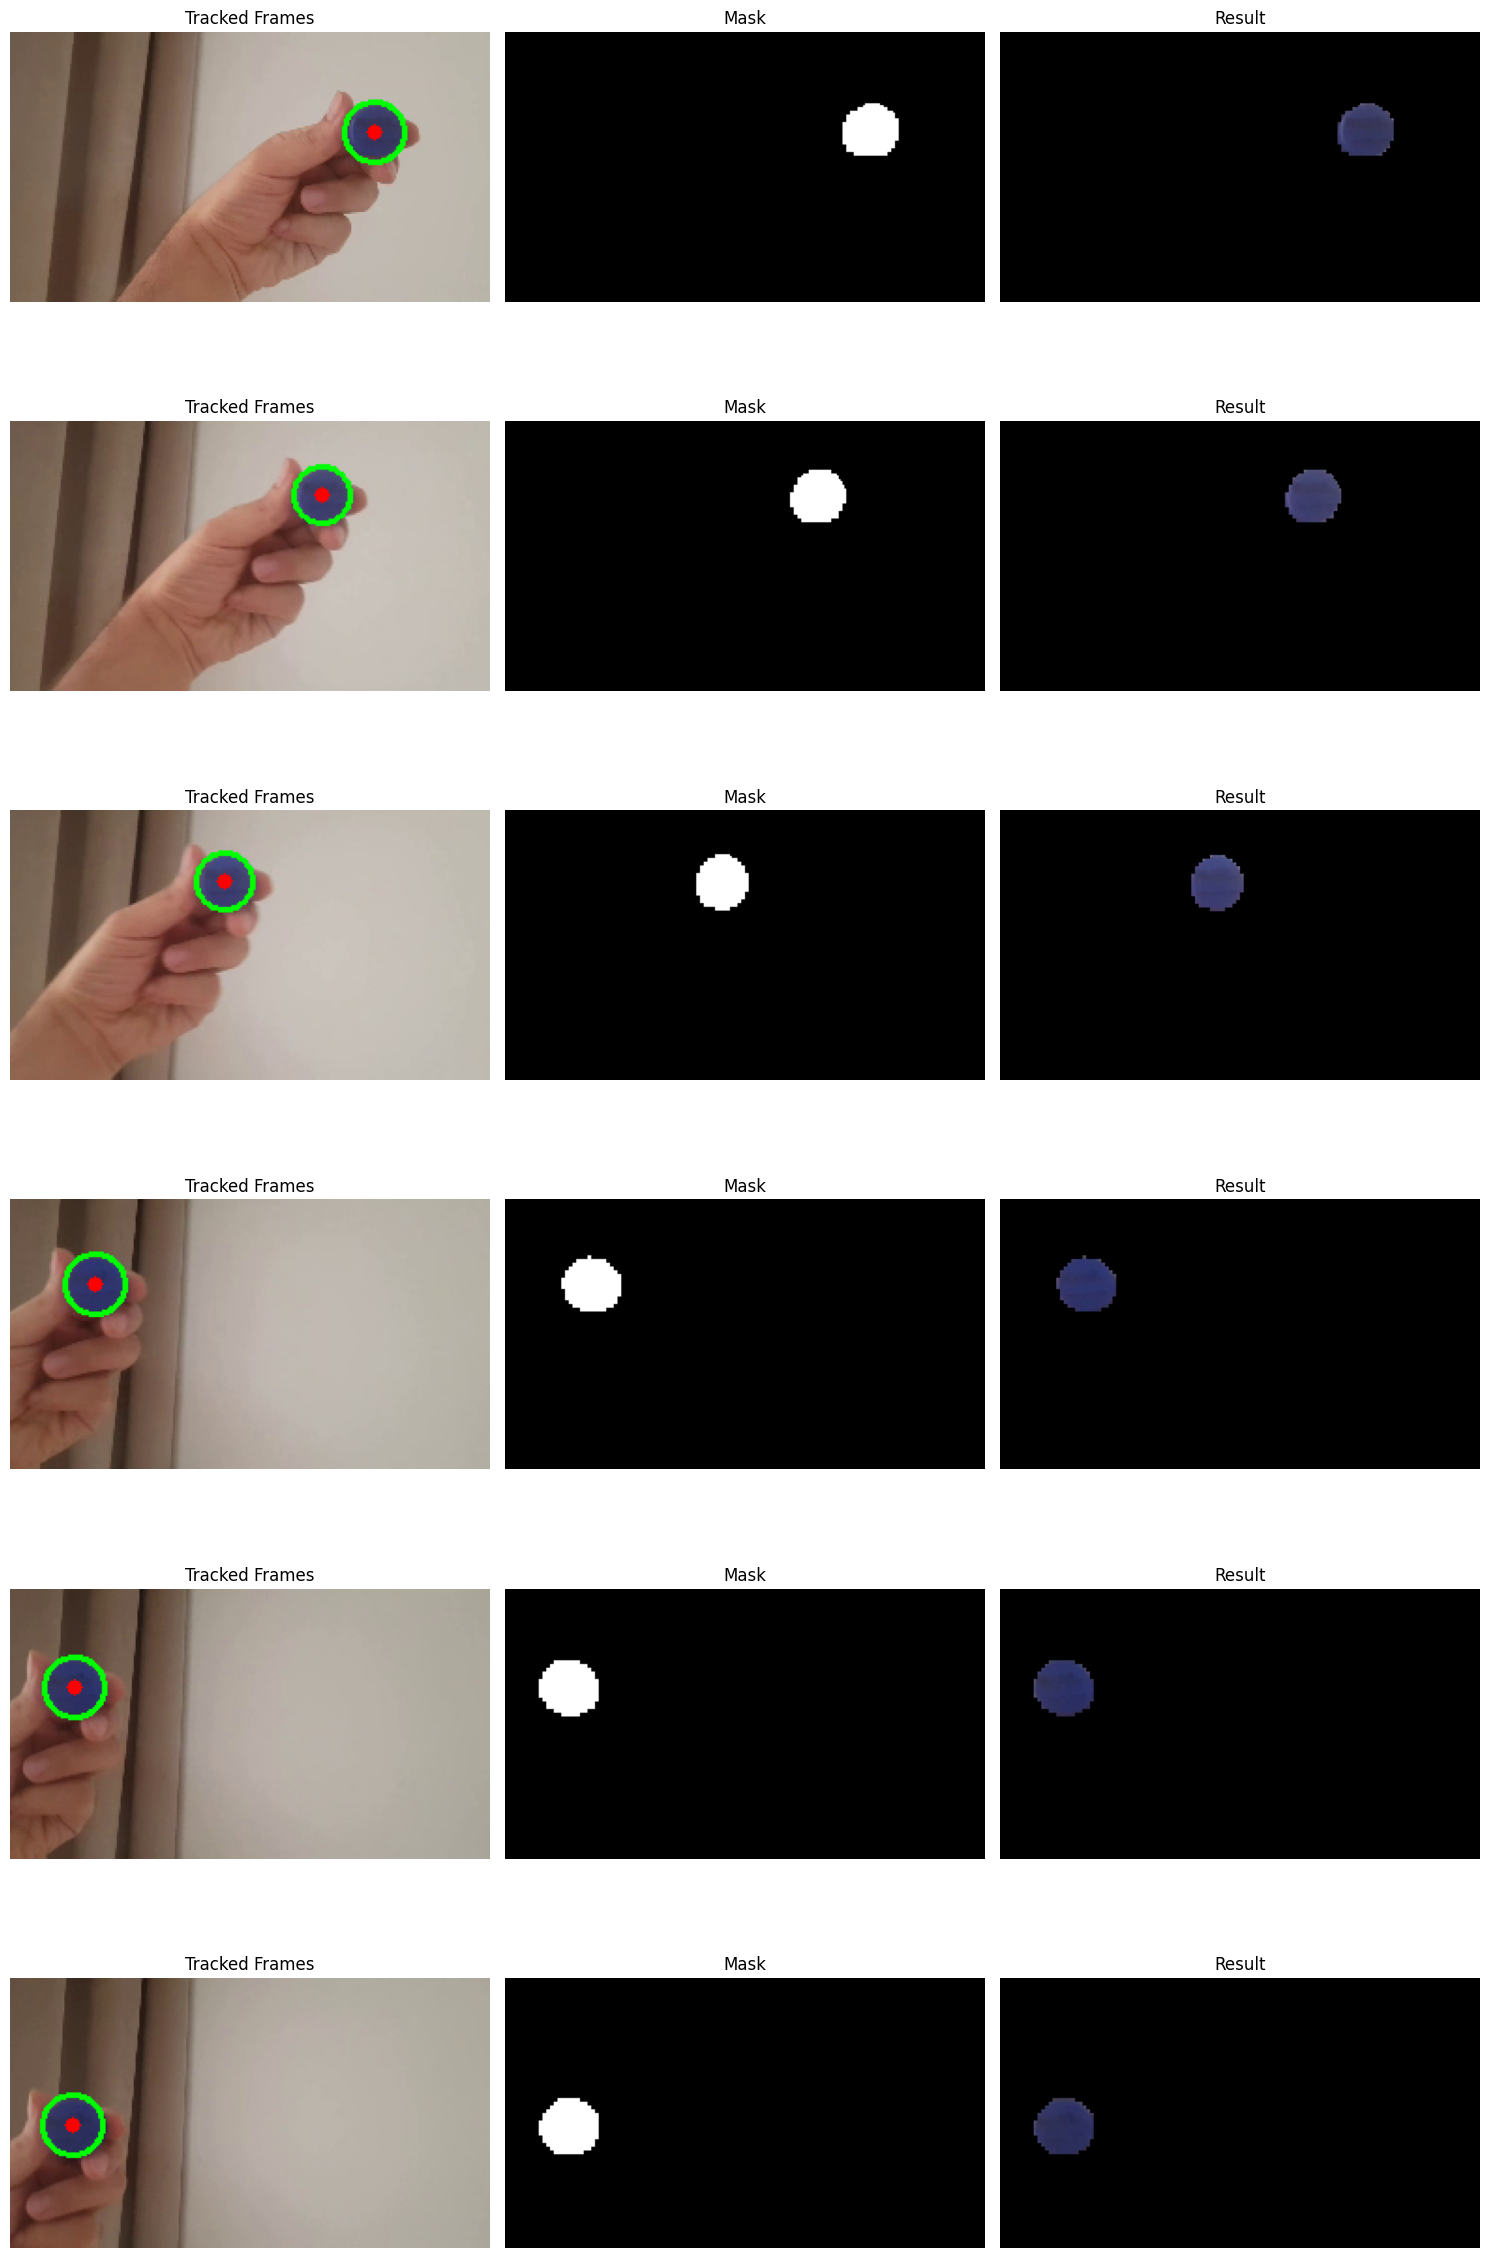

In [8]:
if len(sample_frames) == 0:
  raise Exception('No Sample Frames Found')

plt.figure(figsize=(15, 4 * len(sample_frames)))

for index, (tracked_frames, mask, result) in enumerate(sample_frames, start=1):

  plt.subplot(len(sample_frames), 3, 3 * index -2)
  plt.imshow(cv2.cvtColor(tracked_frames, cv2.COLOR_BGR2RGB))
  plt.title('Tracked Frames')
  plt.axis('off')

  plt.subplot(len(sample_frames), 3, 3 * index -1)
  plt.imshow(mask, cmap='gray')
  plt.title('Mask')
  plt.axis('off')

  plt.subplot(len(sample_frames), 3, 3 * index)
  plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
  plt.title('Result')
  plt.axis('off')

plt.tight_layout()
plt.show()

In [10]:
if len(tracked_frames) == 0:
  raise Exception('No Tracked Frames Found')

height, width = tracked_frames[0].shape[:2]
input_cap = cv2.VideoCapture(Video_path)
fps = input_cap.get(cv2.CAP_PROP_FPS)
input_cap.release()

if fps <= 0:
  fps = 20.0

output_video_path = '/content/blue-tracked-output.mp4'

writer = cv2.VideoWriter(output_video_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (width, height))

for frame in tracked_frames:
  writer.write(frame)

writer.release()
print('Output Video Saved:', output_video_path)

Output Video Saved: /content/blue-tracked-output.mp4


In [11]:
last_frame, last_mask, last_result = sample_frames[-1]

output_images = {
    'Last_Frame': last_frame,
    'Last_Mask': last_mask,
    'Last_Result': last_result
}

for filename, output_image in output_images.items():
  output_path = f'/content/{filename}.png'
  cv2.imwrite(output_path, output_image)
  print(f'{filename} Saved:', output_path)
  files.download(output_path)
  print(f'{filename} Downloaded:', output_path)

Last_Frame Saved: /content/Last_Frame.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Last_Frame Downloaded: /content/Last_Frame.png
Last_Mask Saved: /content/Last_Mask.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Last_Mask Downloaded: /content/Last_Mask.png
Last_Result Saved: /content/Last_Result.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Last_Result Downloaded: /content/Last_Result.png
